In [134]:
# Import all of the python packages used in this workflow.
import scipy
import numpy as np
from collections import OrderedDict
import os, sys
from pylab import *
import pandas as pd
import numpy as np
import osr
import xarray as xr
import geopandas as gpd
from datetime import datetime
from datetime import timedelta  
import json
import matplotlib.pyplot as plt
import requests

#from sklearn.covariance import EmpiricalCovariance, MinCovDet

In [135]:
########## USER ###########
# Select modeling domain ('WY', 'UT', 'OR', 'WA')
domain = 'TR'

# SM location 
SMpath = '/nfs/attic/dfh/Aragon2/CSOsm/jan2021_snowmodel-dfhill_'+domain+'/'

run_date = '2025-04-11'

In [136]:
# Outfile path
outpath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'
calpath = '/nfs/attic/dfh/Aragon2/CSOcal/'+domain+'/'
# Figure path
figpath = '/nfs/attic/dfh/Aragon2/CSOfigs/'+domain+'/'

##path to CSO domain json
#with open('/nfs/attic/dfh/Aragon2/CSOdata/CSO_domains.json') as f:
#    domains = json.load(f)

#path to CSO domains
domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()

#start date    
st = domains[domain]['st']
#end date
ed = domains[domain]['ed']

#Snotel bounding box
Bbox = domains[domain]['Bbox']

# Snotel projection
stn_proj = domains[domain]['stn_proj']
# model projection
mod_proj = domains[domain]['mod_proj']

In [137]:
domains[domain]

{'name': 'TR',
 'Bbox': {'latmax': 39.62,
  'latmin': 38.68,
  'lonmax': -119.76,
  'lonmin': -120.48},
 'st': '2015-09-01',
 'ed': '2019-08-31',
 'stn_proj': 'epsg:4326',
 'mod_proj': 'epsg:32611',
 'ncols': '1317',
 'nrows': '2131',
 'xll': '197250',
 'yll': '4284850',
 'cellsize': '50'}

In [139]:
gdf = gpd.read_file(outpath+'CSO_SNOTEL_sites_'+domain+'.geojson')
df = pd.read_csv(outpath+'SNOTEL_'+domain+'_SWEDmeters'+st+'_'+ed+'.csv') 
gdf.head()

,code,longitude,latitude,name,elevation_m,easting,northing,geometry
0,340_NV_SNTL,-119.942200,39.455002,Big Meadow,2510.028076171875,246847.901984,4.371403e+06,POINT (-119.94220 39.45500)
1,1051_CA_SNTL,-119.894203,38.719429,Burnside Lake,2477.71923828125,248375.624460,4.289619e+06,POINT (-119.89420 38.71943)
2,1067_CA_SNTL,-120.002197,38.692699,Carson Pass,2548.1279296875,238887.375757,4.286955e+06,POINT (-120.00220 38.69270)
3,428_CA_SNTL,-120.368073,39.325649,Css Lab,2101.291259765625,209661.057788,4.358327e+06,POINT (-120.36807 39.32565)
4,463_CA_SNTL,-120.079498,38.848999,Echo Peak,2332.634521484375,232747.300201,4.304528e+06,POINT (-120.07950 38.84900)


In [140]:
#data = xr.open_dataset(calpath+'calibration_'+run_date+'_full_set.nc') - not sure why 'full set' is in the name here.
data = xr.open_dataset(calpath+'calibration_'+run_date+'.nc')
data

<xarray.Dataset>
Dimensions:          (calibration_run: 1800, metric: 5, station: 21)
Coordinates:
  * calibration_run  (calibration_run) int64 0 1 2 3 4 ... 1796 1797 1798 1799
  * metric           (metric) object 'R2' 'MBE' 'RMSE' 'NSE' 'KGE'
  * station          (station) object '340_NV_SNTL' ... '848_CA_SNTL'
Data variables:
    cal_metrics      (calibration_run, metric, station) float64 ...
Attributes:
    description:             SnowModel line calibration performance metrics
    calibration_parameters:  ro_snowmax,cf_precip_scalar,ro_adjust
    model_parameter:         SWE [m]

In [141]:
#swes = xr.open_dataset(calpath+'swe_'+run_date+'_full_set.nc') - not sure why full set is in title
swes = xr.open_dataset(calpath+'swe_'+run_date+'.nc')
swes

<xarray.Dataset>
Dimensions:          (calibration_run: 1800, sim_day: 1461, station: 21)
Coordinates:
  * calibration_run  (calibration_run) int64 0 1 2 3 4 ... 1796 1797 1798 1799
  * sim_day          (sim_day) int64 0 1 2 3 4 5 ... 1456 1457 1458 1459 1460
  * station          (station) object '340_NV_SNTL' ... '848_CA_SNTL'
Data variables:
    cal_metrics      (calibration_run, sim_day, station) float64 ...
Attributes:
    description:      SnowModel swe
    model_parameter:  SWE [m]

In [142]:
#'cal_params_2020-07-03_full_set.csv'
#calibration = pd.read_csv(calpath+'cal_params_'+run_date+'_full_set.csv') - not sure why full set is in title?
calibration = pd.read_csv(calpath+'cal_params_'+run_date+'.csv')
calibration.head()

,max_layers,ro_snowmax,ro_adjust,cf_precip_scalar,conifer_lai,gap_frac
0,1,400.0,4.0,0.6,1.5,0.2
1,1,400.0,4.0,0.6,1.5,0.4
2,1,400.0,4.0,0.6,1.5,0.6
3,1,400.0,4.0,0.6,1.5,0.8
4,1,400.0,4.0,0.6,1.8,0.2


In [143]:
# # sidebar to find top performance metrics across domains with pr cf = 1
# cf1data = data.sel(calibration_run=calibration.index[calibration.cf_precip_scalar==1])

# NSE = cf1data.cal_metrics.loc[:,"NSE",:]
# nse_top = np.amax(cf1data.cal_metrics.loc[:,"NSE",:],axis = 0)
# KGE = cf1data.cal_metrics.loc[:,"KGE",:]
# kge_top = np.amax(cf1data.cal_metrics.loc[:,"KGE",:],axis = 0)
# RMSE = cf1data.cal_metrics.loc[:,"RMSE",:]
# rmse_top = np.amin(cf1data.cal_metrics.loc[:,"RMSE",:],axis = 0)
# R_2 = cf1data.cal_metrics.loc[:,"R2",:]
# r2_top = np.amax(cf1data.cal_metrics.loc[:,"R2",:],axis = 0)
# MBE = cf1data.cal_metrics.loc[:,"MBE",:]
# mbe_top = np.amin(cf1data.cal_metrics.loc[:,"MBE",:],axis = 0)
# print(nse_top)

# x = np.empty((len(cf1data.calibration_run),5))
# x[:,0] = np.mean(NSE.values,axis=1)
# x[:,1] = np.mean(KGE,axis=1).values
# x[:,2] = np.mean(RMSE,axis=1).values
# x[:,3] = np.mean(R_2,axis=1).values
# x[:,4] = np.mean(MBE,axis=1).values

# dataav = pd.DataFrame(x,columns=['NSE', 'KGE', 'RMSE','R_2','MBE'])

# def get_top_idx(metric):
#     if (metric == 'R_2') | (metric == 'NSE')|(metric == 'KGE'):
#         x = dataav[metric].values
#         index = np.where(x==np.max(x))
#     elif (metric == 'MBE'):
#         x = np.abs(dataav['MBE']).values
#         index = np.where(x==np.min(x))
#     elif (metric == 'RMSE'):
#         x = dataav[metric]
#         index = np.where(x==np.min(x))
#     return index[0][0]


# top_params = []

# top_params.append(get_top_idx('R_2'))
# top_params.append(get_top_idx('MBE'))
# top_params.append(get_top_idx('RMSE'))
# top_params.append(get_top_idx('NSE'))
# top_params.append(get_top_idx('KGE'))

# print(domain)
# cal_subset = calibration[calibration.cf_precip_scalar==1]
# topav = cal_subset.iloc[top_params]
# topav = topav.reset_index(drop=True)
# topav

# Find average top performing metrics 
For a given OF, take the average skill score across all stations

In [144]:
NSE = data.cal_metrics.loc[:,"NSE",:]
nse_top = np.amax(data.cal_metrics.loc[:,"NSE",:],axis = 0)
KGE = data.cal_metrics.loc[:,"KGE",:]
kge_top = np.amax(data.cal_metrics.loc[:,"KGE",:],axis = 0)
RMSE = data.cal_metrics.loc[:,"RMSE",:]
rmse_top = np.amin(data.cal_metrics.loc[:,"RMSE",:],axis = 0)
R_2 = data.cal_metrics.loc[:,"R2",:]
r2_top = np.amax(data.cal_metrics.loc[:,"R2",:],axis = 0)
MBE = data.cal_metrics.loc[:,"MBE",:]
mbe_top = np.amin(data.cal_metrics.loc[:,"MBE",:],axis = 0)

print('maxNSE:', r2_top)

maxNSE: <xarray.DataArray 'cal_metrics' (station: 21)>
array([0.98290781, 0.99037836, 0.97328363, 0.96126715, 0.98029096,
       0.97367369, 0.98673435, 0.973504  , 0.97376537, 0.98472726,
       0.83893827, 0.91863357, 0.98909214, 0.94418171, 0.97204322,
       0.99167803, 0.98451635, 0.99177764, 0.95074889, 0.96769107,
       0.97266877])
Coordinates:
    metric   <U2 'R2'
  * station  (station) object '340_NV_SNTL' '1051_CA_SNTL' ... '848_CA_SNTL'


Text(0.5, 1.0, 'R**2')

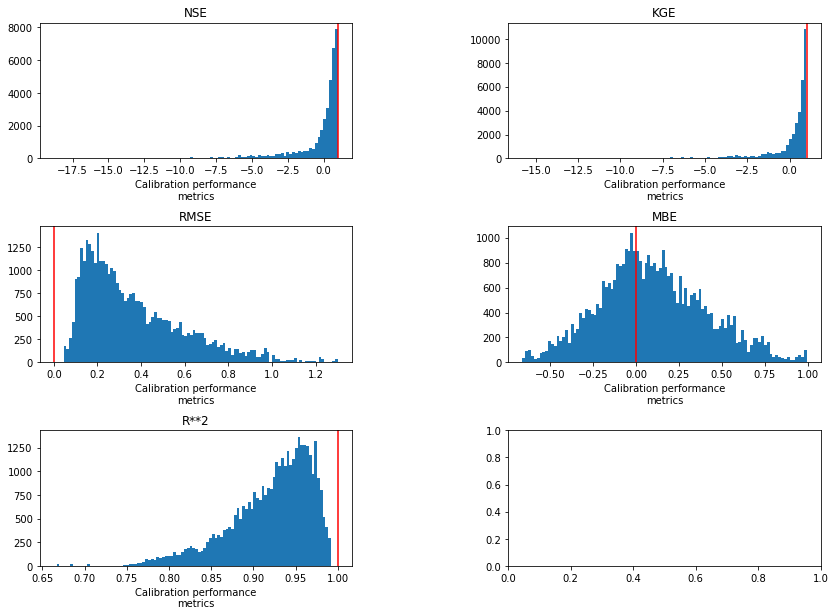

In [145]:
fig, axes = plt.subplots(ncols=2,nrows=3,figsize=(14, 10))
fig.subplots_adjust(hspace = .5, wspace=.5)
axes[0,0].axvline(1,c='r') 
NSE.plot.hist(ax=axes[0,0],bins=100)
axes[0,0].set_title('NSE')
axes[0,1].axvline(1,c='r') 
KGE.plot.hist(ax=axes[0,1],bins=100)
axes[0,1].set_title('KGE')
axes[1,0].axvline(0,c='r') 
RMSE.plot.hist(ax=axes[1,0],bins=100)
axes[1,0].set_title('RMSE')
axes[1,1].axvline(0,c='r') 
MBE.plot.hist(ax=axes[1,1],bins=100)
axes[1,1].set_title('MBE')
axes[2,0].axvline(1,c='r') 
R_2.plot.hist(ax=axes[2,0],bins=100)
axes[2,0].set_title('R**2')

In [146]:
fig.savefig(figpath+domain+'_domain_cal_metrics.pdf', format='pdf', dpi=300)

### Data frame of metrics averaged over domain for each model run

In [147]:
x = np.empty((len(calibration),5))
x[:,0] = np.mean(NSE.values,axis=1)
x[:,1] = np.mean(KGE,axis=1).values
x[:,2] = np.mean(RMSE,axis=1).values
x[:,3] = np.mean(R_2,axis=1).values
x[:,4] = np.mean(MBE,axis=1).values

dataav = pd.DataFrame(x,columns=['NSE', 'KGE', 'RMSE','R_2','MBE'])
dataav
#dataav.to_csv('calibration_params.csv')

,NSE,KGE,RMSE,R_2,MBE
0,0.286226,0.462354,0.345742,0.890933,-0.264462
1,0.216052,0.402040,0.364059,0.869352,-0.277690
2,0.158454,0.348373,0.377419,0.848861,-0.286622
3,0.107031,0.297625,0.387692,0.829465,-0.293290
4,0.301348,0.477066,0.341367,0.896607,-0.261947
...,...,...,...,...,...
1795,-4.112453,-2.871781,0.685844,0.902064,0.499249
1796,-4.873682,-3.449819,0.773221,0.870743,0.571597
1797,-4.615711,-3.249965,0.744284,0.881970,0.551889
1798,-4.342768,-3.040741,0.711662,0.893428,0.525327


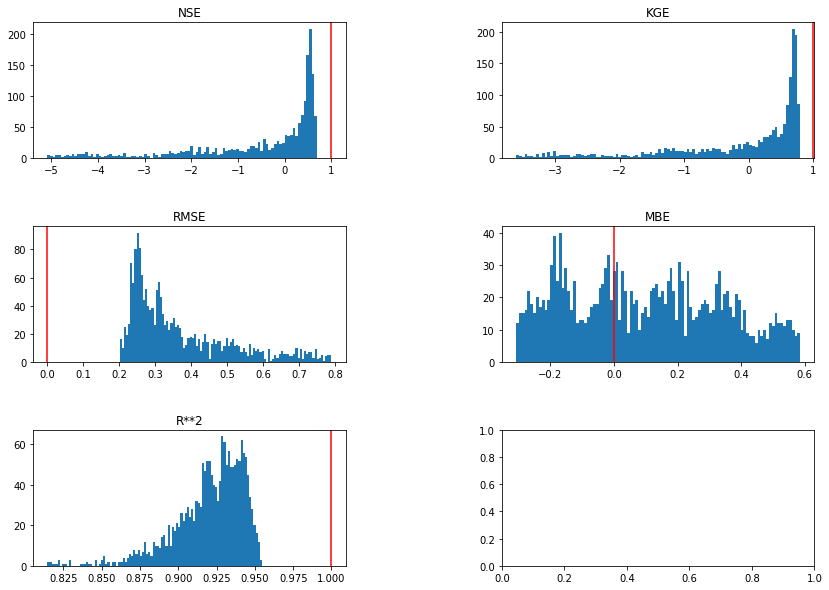

In [148]:
fig, axs = plt.subplots(3, 2,figsize=(14, 10))
fig.subplots_adjust(hspace = .5, wspace=.5)
axs[0, 0].hist(dataav['NSE'],bins=100)
axs[0, 0].set_title('NSE')
axs[0, 0].axvline(1,c='r') 
axs[0, 1].hist(dataav['KGE'],bins=100)
axs[0, 1].set_title('KGE')
axs[0, 1].axvline(1,c='r') 
axs[1, 0].hist(dataav['RMSE'],bins=100)
axs[1, 0].set_title('RMSE')
axs[1, 0].axvline(0,c='r') 
axs[1, 1].hist(dataav['MBE'],bins=100)
axs[1, 1].set_title('MBE')
axs[1, 1].axvline(0,c='r') 
axs[2, 0].hist(dataav['R_2'],bins=100)
axs[2, 0].set_title('R**2')
axs[2, 0].axvline(1,c='r') 

In [149]:
fig.savefig(figpath+domain+'_domain_cal_metrics_averaged.pdf', format='pdf', dpi=300)

In [150]:
def get_top_idx(metric):
    if (metric == 'R_2') | (metric == 'NSE')|(metric == 'KGE'):
        x = dataav[metric].values
        index = np.where(x==np.max(x))
    elif (metric == 'MBE'):
        x = np.abs(dataav['MBE']).values
        index = np.where(x==np.min(x))
    elif (metric == 'RMSE'):
        x = dataav[metric]
        index = np.where(x==np.min(x))
    return index[0][0]


top_params = []

top_params.append(get_top_idx('R_2'))
top_params.append(get_top_idx('MBE'))
top_params.append(get_top_idx('RMSE'))
top_params.append(get_top_idx('NSE'))
top_params.append(get_top_idx('KGE'))

top_params

[340, 1020, 824, 324, 324]

In [152]:
#the parameters for the top performing runs
print(domain)
topav = calibration.iloc[top_params]
topav = topav.reset_index(drop=True)
topav

TR


,max_layers,ro_snowmax,ro_adjust,cf_precip_scalar,conifer_lai,gap_frac
0,1,450.0,4.0,1.0,1.5,0.2
1,1,550.0,5.0,0.8,1.5,0.2
2,1,500.0,6.0,0.8,1.8,0.2
3,1,450.0,4.0,0.8,1.8,0.2
4,1,450.0,4.0,0.8,1.8,0.2


### Heatmap of top performing runs 

In [153]:
#https://matplotlib.org/3.1.1/gallery/images_contours_and_fields/image_annotated_heatmap.html
def heatmap(data, row_labels, col_labels, ax=None,
            cbar_kw={}, cbarlabel="", **kwargs):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (N, M).
    row_labels
        A list or array of length N with the labels for the rows.
    col_labels
        A list or array of length M with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if not ax:
        ax = plt.gca()

    # Plot the heatmap
    im = ax.imshow(data, vmin=-1, vmax=1, **kwargs)

    # Create colorbar
    cbar = ax.figure.colorbar(im, ax=ax, **cbar_kw)
    cbar.ax.set_ylabel(cbarlabel, rotation=-90, va="bottom")

    # We want to show all ticks...
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    # ... and label them with the respective list entries.
    ax.set_xticklabels(col_labels)
    ax.set_yticklabels(row_labels)

    # Let the horizontal axes labeling appear on top.
    ax.tick_params(top=True, bottom=False,
                   labeltop=True, labelbottom=False)

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=-30, ha="right",
             rotation_mode="anchor")

    # Turn spines off and create white grid.
    for edge, spine in ax.spines.items():
        spine.set_visible(False)

    ax.set_xticks(np.arange(data.shape[1]+1)-.5, minor=True)
    ax.set_yticks(np.arange(data.shape[0]+1)-.5, minor=True)
    ax.grid(which="minor", color="w", linestyle='-', linewidth=3)
    ax.tick_params(which="minor", bottom=False, left=False)

    return im, cbar


def annotate_heatmap(im, data=None, valfmt="{x:.2f}",
                     textcolors=["black", "white"],
                     threshold=None, **textkw):
    """
    A function to annotate a heatmap.

    Parameters
    ----------
    im
        The AxesImage to be labeled.
    data
        Data used to annotate.  If None, the image's data is used.  Optional.
    valfmt
        The format of the annotations inside the heatmap.  This should either
        use the string format method, e.g. "$ {x:.2f}", or be a
        `matplotlib.ticker.Formatter`.  Optional.
    textcolors
        A list or array of two color specifications.  The first is used for
        values below a threshold, the second for those above.  Optional.
    threshold
        Value in data units according to which the colors from textcolors are
        applied.  If None (the default) uses the middle of the colormap as
        separation.  Optional.
    **kwargs
        All other arguments are forwarded to each call to `text` used to create
        the text labels.
    """

    if not isinstance(data, (list, np.ndarray)):
        data = im.get_array()

    # Normalize the threshold to the images color range.
    if threshold is not None:
        threshold = im.norm(threshold)
    else:
        threshold = im.norm(data.max())/2.

    # Set default alignment to center, but allow it to be
    # overwritten by textkw.
    kw = dict(horizontalalignment="center",
              verticalalignment="center")
    kw.update(textkw)

    # Get the formatter in case a string is supplied
    if isinstance(valfmt, str):
        valfmt = matplotlib.ticker.StrMethodFormatter(valfmt)

    # Loop over the data and create a `Text` for each "pixel".
    # Change the text's color depending on the data.
    texts = []
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            kw.update(color=textcolors[int(im.norm(data[i, j]) > threshold)])
            text = im.axes.text(j, i, valfmt(data[i, j], None), **kw)
            texts.append(text)

    return texts


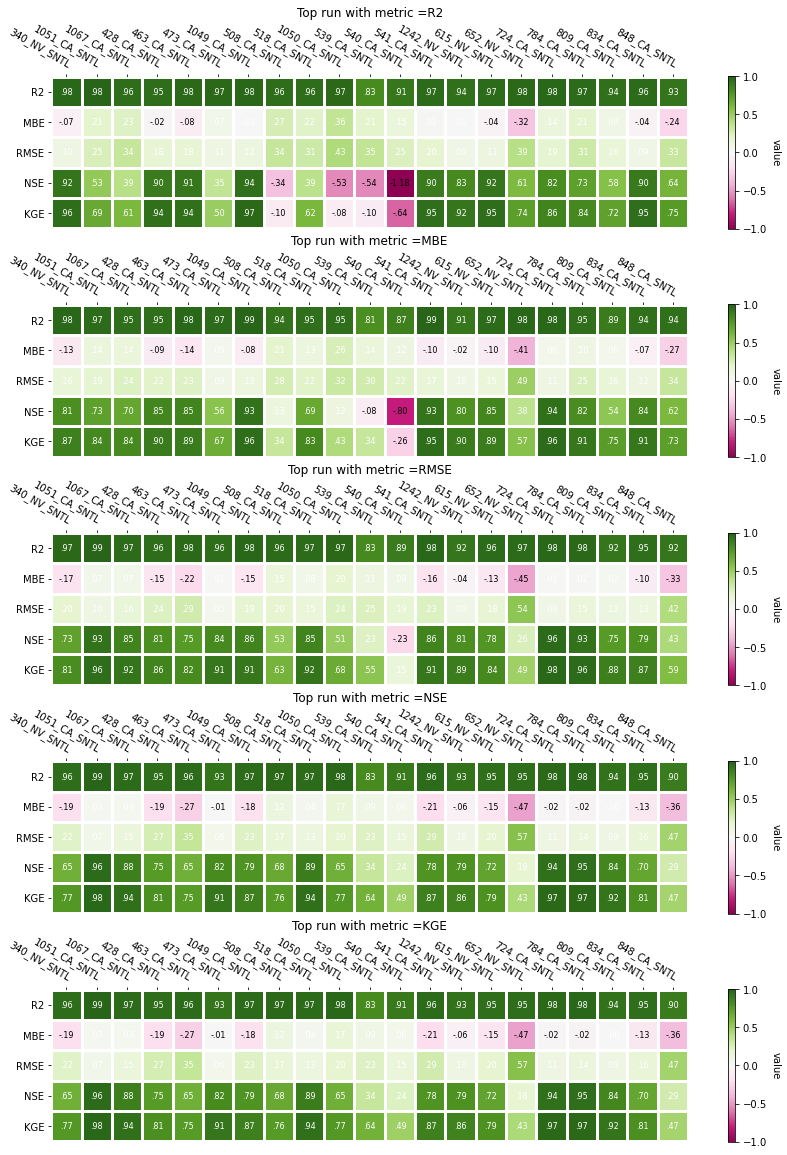

In [154]:
Metrics = ['R2','MBE','RMSE','NSE','KGE']
Stations = gdf['code'].values

def func(x, pos):
    return "{:.2f}".format(x).replace("0.", ".").replace("1.00", "")
#WA figsize=(8,16)
fig, ((ax), (ax1), (ax2), (ax3),(ax4)) = plt.subplots(5, 1, figsize=(12,16))

# Replicate the above example with a different font size and colormap.
im, cbar = heatmap(data.cal_metrics[top_params[0],:,:], Metrics, Stations, ax=ax,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax.set_title('Top run with metric ='+Metrics[0])

im, _ = heatmap(data.cal_metrics[top_params[1],:,:], Metrics, Stations, ax=ax1,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax1.set_title('Top run with metric ='+Metrics[1])

im, _ = heatmap(data.cal_metrics[top_params[2],:,:], Metrics, Stations, ax=ax2,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax2.set_title('Top run with metric ='+Metrics[2])

im, _ = heatmap(data.cal_metrics[top_params[3],:,:], Metrics, Stations, ax=ax3,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax3.set_title('Top run with metric ='+Metrics[3])

im, _ = heatmap(data.cal_metrics[top_params[4],:,:], Metrics, Stations, ax=ax4,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax4.set_title('Top run with metric ='+Metrics[4])


plt.tight_layout()
plt.show()

In [155]:
fig.savefig(figpath+domain+'_heatmap_averaged.pdf', format='pdf', dpi=300)

## SWE timeseries with optimal configurations identified above

In [156]:
inswe = swes.cal_metrics[top_params,:,:]
#inswe = inswe.reset_index(drop=True)
inswe

<xarray.DataArray 'cal_metrics' (calibration_run: 5, sim_day: 1461, station: 21)>
[153405 values with dtype=float64]
Coordinates:
  * calibration_run  (calibration_run) int64 340 1020 824 324 324
  * sim_day          (sim_day) int64 0 1 2 3 4 5 ... 1456 1457 1458 1459 1460
  * station          (station) object '340_NV_SNTL' ... '848_CA_SNTL'
Attributes:
    long_name:      swe timeseries [m]
    standard_name:  swe

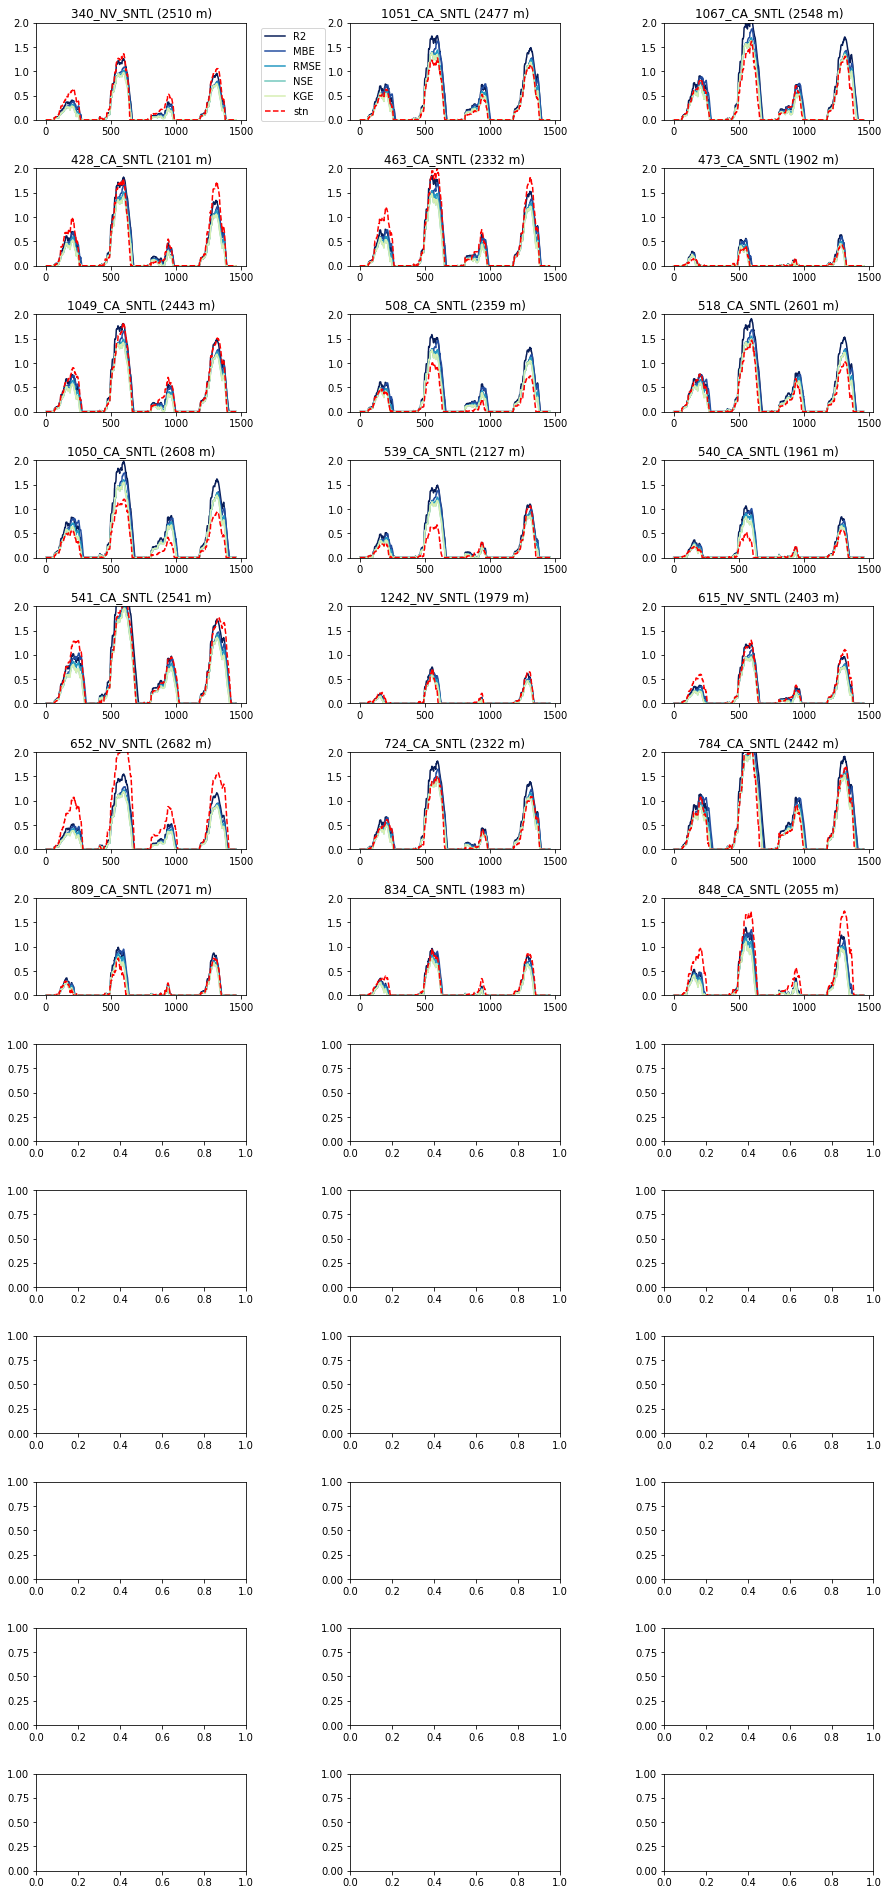

In [157]:
elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
#CO_N: nrows=13,figsize=(15, 34) 
fig, axs = plt.subplots(nrows=13,figsize=(15, 34) , ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = inswe.sel(station = nam).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    for j in range(n):
        c=next(color)
        axs[i].plot(np.transpose(mod[j,:]),c=c)
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(['R2','MBE','RMSE','NSE', 'KGE','stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [158]:
fig.savefig(figpath+domain+'_SWE_top_calmetrics_'+run_date+'_av.pdf', format='pdf', dpi=300)

# Top ranked score

-> each OF is ranked independently

-> the rank scores are summed across each model run 

-> The summed scores are then ranked and the top scores are used to identify the top model parameter combinations

In [159]:
dataav['NSE_rank']=dataav['NSE'].rank(ascending=False)
dataav['KGE_rank']=dataav['KGE'].rank(ascending=False)
dataav['R_2_rank']=dataav['R_2'].rank(ascending=False)
dataav['RMSE_rank']=dataav['RMSE'].rank()
dataav['MBE_rank']=np.abs(dataav['MBE']).rank()
dataav['score']=dataav['NSE_rank']+ dataav['KGE_rank']+dataav['R_2_rank']+ dataav['RMSE_rank']+dataav['MBE_rank']
dataav['score_rank'] = dataav['score'].rank()
dataav.head()

,NSE,KGE,RMSE,R_2,MBE,NSE_rank,KGE_rank,R_2_rank,RMSE_rank,MBE_rank,score,score_rank
0,0.286226,0.462354,0.345742,0.890933,-0.264462,795.0,807.0,1607.0,1066.0,1221.0,5496.0,1151.0
1,0.216052,0.402040,0.364059,0.869352,-0.277690,841.0,872.0,1738.0,1145.0,1276.0,5872.0,1289.5
2,0.158454,0.348373,0.377419,0.848861,-0.286622,888.0,922.0,1775.0,1193.0,1316.0,6094.0,1349.0
3,0.107031,0.297625,0.387692,0.829465,-0.293290,921.0,964.0,1786.0,1211.0,1333.0,6215.0,1387.0
4,0.301348,0.477066,0.341367,0.896607,-0.261947,783.0,801.0,1548.0,1036.0,1212.0,5380.0,1104.5


In [160]:
rank_params = np.where((dataav['score_rank']==min(dataav['score_rank'])))
top_params = rank_params[0]
label = dataav['score_rank'][top_params].values
top_params

array([620])

In [161]:
#the parameters for the top performing runs
toprank = calibration.iloc[top_params]
#toprank = dataav.iloc[top_params]
toprank

,max_layers,ro_snowmax,ro_adjust,cf_precip_scalar,conifer_lai,gap_frac
620,1,500.0,4.0,0.8,1.5,0.2


Text(0.5, 1.0, 'Top Rank')

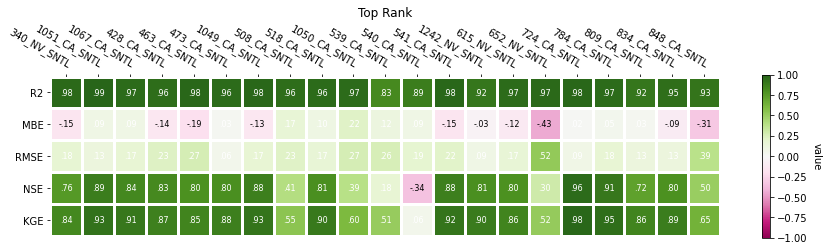

In [162]:
fig, ((ax)) = plt.subplots(1, 1, figsize=(15,3))

# Replicate the above example with a different font size and colormap.
im, cbar = heatmap(data.cal_metrics[top_params[0],:,:], Metrics, Stations, ax=ax,
                   cmap="PiYG", cbarlabel="value")
annotate_heatmap(im, valfmt=matplotlib.ticker.FuncFormatter(func), size=8)
ax.set_title('Top Rank')

In [163]:
fig.savefig(figpath+domain+'_heatmap_rank.pdf', format='pdf', dpi=300)

In [164]:
# #this worked with a smaller calibration parameter set but does not work if their are ties for first place rankings
# rank_params = np.where((dataav['score_rank']==1)|(dataav['score_rank']==2)|(dataav['score_rank']==3))

In [165]:
inswe = swes.cal_metrics[top_params[0],:,:]
inswe

<xarray.DataArray 'cal_metrics' (sim_day: 1461, station: 21)>
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])
Coordinates:
    calibration_run  int64 620
  * sim_day          (sim_day) int64 0 1 2 3 4 5 ... 1456 1457 1458 1459 1460
  * station          (station) object '340_NV_SNTL' ... '848_CA_SNTL'
Attributes:
    long_name:      swe timeseries [m]
    standard_name:  swe

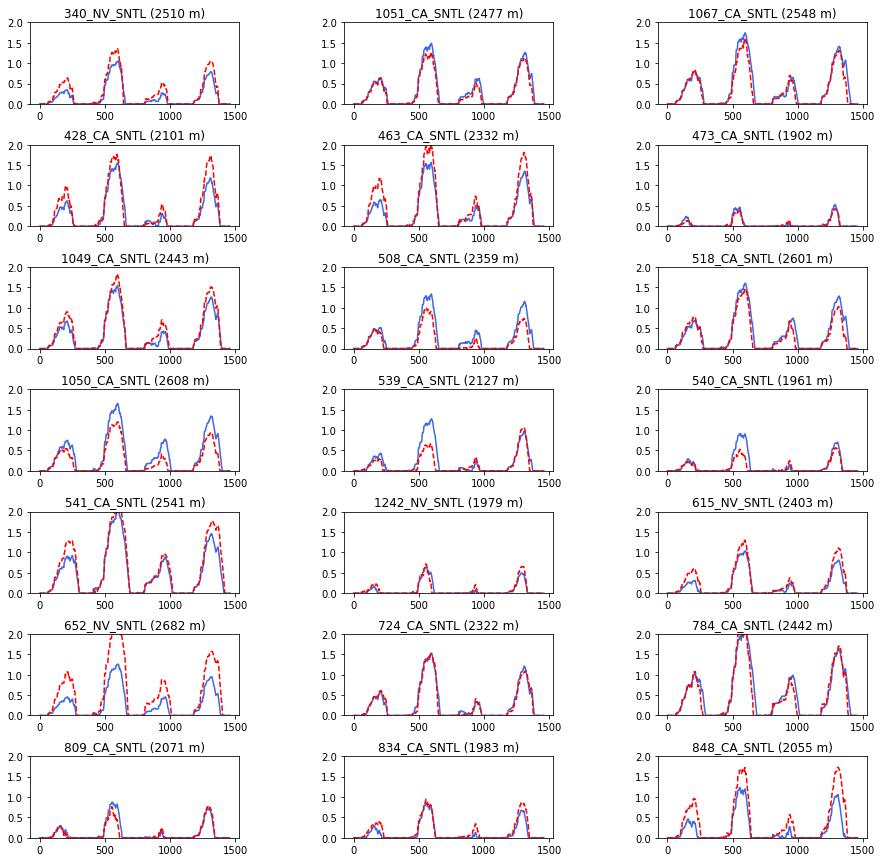

In [168]:
#Ranking plot OR -> one winning rank score 
elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0]

fig, axs = plt.subplots(nrows=7, figsize=(15, 15), ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = inswe[:,i]
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+2)))
    axs[i].plot(mod,c='royalblue')
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
#     if i == 0:
#         axs[i].legend([str(label[0]),str(label[1]),str(label[2]),'stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [169]:
fig.savefig(figpath+domain+'_SWE_top_calmetrics_'+run_date+'_rank.pdf', format='pdf', dpi=300)

# Set up full run of SM based on above findings

In [39]:
OF = 'NSE'

#the parameters for the top performing runs
calibration.loc[get_top_idx(OF)]

max_layers            1.0
ro_snowmax          500.0
ro_adjust             6.0
cf_precip_scalar      1.4
conifer_lai           1.5
gap_frac              0.2
Name: 880, dtype: float64

In [40]:
calibration.conifer_lai.loc[get_top_idx(OF)]

1.5

In [ ]:
# run line model of SM with top params


parFile = SMpath+'snowmodel.par'
incFile = SMpath+'code/snowmodel.inc'
codepath = SMpath+'code'
calpath = '/nfs/attic/dfh/Aragon2/Notebooks/calibration_python'
micrometFile = SMpath+'code/micromet_code.f'


#function to edit SnowModel Files other than .par
def replace_line(file_name, line_num, text):
    lines = open(file_name, 'r').readlines()
    lines[line_num] = text
    out = open(file_name, 'w')
    out.writelines(lines)
    out.close()

#Edit the par file to set parameters with new values
def edit_par(par_dict,parameter,new_value,parFile):
    lines = open(parFile, 'r').readlines()
    if par_dict[parameter][2] == 14 or par_dict[parameter][2] == 17 \
    or par_dict[parameter][2] == 18 or par_dict[parameter][2] == 19 \
    or par_dict[parameter][2] == 93 or par_dict[parameter][2] == 95 \
    or par_dict[parameter][2] == 97 or par_dict[parameter][2] == 100 \
    or par_dict[parameter][2] == 102 or par_dict[parameter][2] == 104 \
    or par_dict[parameter][2] == 107 or par_dict[parameter][2] == 108 \
    or par_dict[parameter][2] == 147 or par_dict[parameter][2] == 148 \
    or par_dict[parameter][2] == 149:
        text = str(new_value)+'\n'
    else:
        text = str(new_value)+'\t\t\t!'+par_dict[parameter][1]
    lines[par_dict[parameter][2]] = text
    out = open(parFile, 'w')
    out.writelines(lines)
    out.close()
    
#base .par
basepar_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/calibration_python/master/par_base.json")
base = basepar_resp.json()

##edit snowmodel.inc
replace_line(incFile, 12, '      parameter (nx_max='+str(np.shape(gdf)[0]+1)+',ny_max=2)\n')
replace_line(micrometFile, 3336,'      data vlai_summer /'+str(calibration.conifer_lai.loc[get_top_idx(OF)])+', 2.5, 2.5, 1.5, 1.0/\n')
replace_line(micrometFile, 3337,'      data vlai_winter /'+str(calibration.conifer_lai.loc[get_top_idx(OF)])+', 0.5, 1.5, 1.5, 1.0/\n')

edit_par(base,'snowmodel_line_flag',1,parFile)
edit_par(base,'topo_ascii_fname','../../CSOdmn/'+domain+'/DEM_'+domain+'_line.asc',parFile)
edit_par(base,'veg_ascii_fname','../../CSOdmn/'+domain+'/NLCD2016_'+domain+'_line.asc',parFile)
edit_par(base,'lat_file_path','../../CSOdmn/'+domain+'/grid_lat_'+domain+'_line.asc',parFile)
edit_par(base,'lon_file_path','../../CSOdmn/'+domain+'/grid_lon_'+domain+'_line.asc',parFile)
edit_par(base,'nx',np.shape(gdf)[0],parFile)
edit_par(base,'ny',1,parFile)
edit_par(base,'ro_snowmax',calibration.ro_snowmax.loc[get_top_idx(OF)],parFile)
edit_par(base,'cf_precip_scalar',calibration.cf_precip_scalar.loc[get_top_idx(OF)],parFile)
edit_par(base,'ro_adjust',calibration.ro_adjust.loc[get_top_idx(OF)],parFile) 
edit_par(base,'gap_frac',calibration.gap_frac.loc[get_top_idx(OF)],parFile) 
edit_par(base,'print_var_01','y',parFile)#tair
edit_par(base,'print_var_09','y',parFile)#prec
edit_par(base,'print_var_10','n',parFile)#rain
edit_par(base,'print_var_11','n',parFile)#sprec
edit_par(base,'print_var_12','n',parFile)#swemelt
edit_par(base,'print_var_14','n',parFile)#runoff
edit_par(base,'print_var_18','y',parFile)#swed
edit_par(base,'print_var_19','y',parFile)#sspr
edit_par(base,'print_var_20','y',parFile)#ssmt


    
#run compile script 
#Compile SnowModel

%cd $codepath
! ./compile_snowmodel.script
%cd  $calpath

In [ ]:
# need to discuss how to choose the top - currently set up to analyze based on OF
# SM location 
#SMpath = '/nfs/attic/dfh/Aragon2/mar2020_snowmodel-dfhillWY/'


parFile = SMpath+'snowmodel.par'
incFile = SMpath+'code/snowmodel.inc'
codepath = SMpath+'code'
calpath = '/nfs/attic/dfh/Aragon2/Notebooks/calibration_python'
micrometFile = SMpath+'code/micromet_code.f'


#function to edit SnowModel Files other than .par
def replace_line(file_name, line_num, text):
    lines = open(file_name, 'r').readlines()
    lines[line_num] = text
    out = open(file_name, 'w')
    out.writelines(lines)
    out.close()

#Edit the par file to set parameters with new values
def edit_par(par_dict,parameter,new_value,parFile):
    lines = open(parFile, 'r').readlines()
    if par_dict[parameter][2] == 14 or par_dict[parameter][2] == 17 \
    or par_dict[parameter][2] == 18 or par_dict[parameter][2] == 19 \
    or par_dict[parameter][2] == 93 or par_dict[parameter][2] == 95 \
    or par_dict[parameter][2] == 97 or par_dict[parameter][2] == 100 \
    or par_dict[parameter][2] == 102 or par_dict[parameter][2] == 104 \
    or par_dict[parameter][2] == 107 or par_dict[parameter][2] == 108 \
    or par_dict[parameter][2] == 147 or par_dict[parameter][2] == 148 \
    or par_dict[parameter][2] == 149:
        text = str(new_value)+'\n'
    else:
        text = str(new_value)+'\t\t\t!'+par_dict[parameter][1]
    lines[par_dict[parameter][2]] = text
    out = open(parFile, 'w')
    out.writelines(lines)
    out.close()
    
#base .par
basepar_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/calibration_python/master/par_base.json")
base = basepar_resp.json()

##edit snowmodel.inc
replace_line(incFile, 12, '      parameter (nx_max='+str(int(domains[domain]['ncols'])+1)
             +',ny_max='+str(int(domains[domain]['nrows'])+1)+')\n')#full domain
replace_line(micrometFile, 3336,'      data vlai_summer /'+str(calibration.conifer_lai.loc[get_top_idx(OF)])+', 2.5, 2.5, 1.5, 1.0/\n')
replace_line(micrometFile, 3337,'      data vlai_winter /'+str(calibration.conifer_lai.loc[get_top_idx(OF)])+', 0.5, 1.5, 1.5, 1.0/\n')

#remove line flag
edit_par(base,'snowmodel_line_flag',0,parFile)
edit_par(base,'topo_ascii_fname','../../CSOdmn/'+domain+'/DEM_'+domain+'.asc',parFile)
edit_par(base,'veg_ascii_fname','../../CSOdmn/'+domain+'/NLCD2016_'+domain+'.asc',parFile)
edit_par(base,'lat_file_path','../../CSOdmn/'+domain+'/grid_lat_'+domain+'.asc',parFile)
edit_par(base,'lon_file_path','../../CSOdmn/'+domain+'/grid_lon_'+domain+'.asc',parFile)
edit_par(base,'nx',domains[domain]['ncols'],parFile)
edit_par(base,'ny',domains[domain]['nrows'],parFile)
#edit_par(base,'lat_solar_flag',calibration.lat_solar_flag.loc[get_top_idx(OF)])
#edit_par(base,'wind_lapse_rate',calibration.wind_lapse_rate.loc[get_top_idx(OF)])
#edit_par(base,'lapse_rate',calibration.lapse_rate.loc[get_top_idx(OF)])
#edit_par(base,'prec_lapse_rate',calibration.prec_lapse_rate.loc[get_top_idx(OF)])
edit_par(base,'ro_snowmax',calibration.ro_snowmax.loc[get_top_idx(OF)],parFile)
edit_par(base,'cf_precip_scalar',calibration.cf_precip_scalar.loc[get_top_idx(OF)],parFile)
edit_par(base,'ro_adjust',calibration.ro_adjust.loc[get_top_idx(OF)],parFile) 
edit_par(base,'gap_frac',calibration.gap_frac.loc[get_top_idx(OF)],parFile) 
edit_par(base,'print_var_01','y',parFile)#tair
edit_par(base,'print_var_09','y',parFile)#prec
edit_par(base,'print_var_10','n',parFile)#rain
edit_par(base,'print_var_11','n',parFile)#sprec
edit_par(base,'print_var_12','n',parFile)#swemelt
edit_par(base,'print_var_14','n',parFile)#runoff
edit_par(base,'print_var_18','y',parFile)#swed
edit_par(base,'print_var_19','y',parFile)#sspr
edit_par(base,'print_var_20','y',parFile)#ssmt
#edit_par(base,'run_snowtran',1,parFile)


    
#run compile script 
#Compile SnowModel

%cd $codepath
! ./compile_snowmodel.script
%cd  $calpath

In [ ]:
#Edit
datapath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'
SMpath_extra = SMpath+'/extra_met/'
#have to change out extramet files to use full domain - not line
latpath = datapath+'grid_lat.asc'
lonpath = datapath+'grid_lon.asc'
!cp $latpath $SMpath_extra
!cp $lonpath $SMpath_extra

# #remove hohup file 
# nohup = '/nfs/attic/dfh/Aragon2/mar2020_snowmodel-dfhill'+domain+'/nohup.out'
# !rm $nohup

# in command line - initiate the full model run
# $ cd /nfs/attic/dfh/Aragon2/mar2020_snowmodel-dfhill_full/
# $ ! nohup ./snowmodel

# Compare line output to saved calibration output 

In [ ]:
#https://github.com/miniufo/xgrads/issues/23
#https://cablab.readthedocs.io/en/latest/dat_python.html

In [ ]:
def get_mod_output_lines(inFile):
    #open the grads model output file, 'rb' indicates reading from binary file
    grads_data = open(inFile,'rb')
    # convert to a numpy array 
    numpy_data = np.fromfile(grads_data,dtype='float32',count=-1)
    #close grads file 
    grads_data.close()
    #reshape the data
    numpy_data = np.reshape(numpy_data,(num_sim_days,1,np.shape(gdf)[0]))
    #swe only at station point
    data = np.squeeze(numpy_data[:,0,:]) 

    return data

In [ ]:
sweFile = SMpath+'outputs/wo_assim/swed.gdat'
mod_swe = get_mod_output_lines(sweFile)
np.shape(mod_swe)

In [ ]:
sweFile = SMpath+'outputs/wo_assim/swed.gdat'
mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=13, figsize=(15, 34), ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = mod_swe[:,i]#inswe.sel(station = nam).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,c='b')
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(['R2','MBE','RMSE','NSE', 'KGE','stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=4, figsize=(15, 15), ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = inswe.sel(station = nam).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(np.transpose(mod[0,:]),c='b')
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(['R2','MBE','RMSE','NSE', 'KGE','stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
#########################################################################
############################ USER INPUTS ################################
#########################################################################
# DOMAIN
# choose the modeling domain
domain = 'WY'
print(domain)

domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
    
# PATHS
# path to domain data folder 
dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'
# path to store tif files from gee
#TIFpath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/GEE/'
# # path to where you want your output met .dat fime
# OUTpath = 'OR_met_test.dat'#'/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/mm_'+domain+'_2011-2016.dat'

# TIME
# choose if want to set 'manual' or 'auto' date 
date_flag = 'manual'
# If you choose 'manual' set your dates below  
# This will start on the 'begin' date at 0:00 and the last iteration will 
# be on the day before the 'end' date below.
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']
# gee dates 
stdt=st_dt
eddt=(datetime.strptime(ed_dt,'%Y-%m-%d')+timedelta(days=1)).strftime("%Y-%m-%d")

nx = int(domains[domain]['ncols'])
ny = int(domains[domain]['nrows'])
xll = int(domains[domain]['xll'])
yll = int(domains[domain]['yll'])
clsz = int(domains[domain]['cellsize'])

# number of timesteps in model run 
num_mod_timesteps = (datetime.strptime(ed_dt,'%Y-%m-%d')-datetime.strptime(st_dt,'%Y-%m-%d')).days+1
#########################################################################

In [ ]:
dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'

domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']

# load the precip data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_PRmeters'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_pr=dftemp.set_index(dftemp.datetime,drop=True)
stn_pr

In [ ]:
sweFile = SMpath+'outputs/wo_assim/prec_line.gdat'
mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_pr[nam].values
    mod = mod_swe[:,i]#inswe.sel(station = nam).values
    x = np.arange(len(mod))
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].bar(x,mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].bar(x,obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
# load the temp data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_TAVGcelsius'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_temp=dftemp.set_index(dftemp.datetime,drop=True)
stn_temp

In [ ]:
def get_mod_output_lines(inFile):
    #open the grads model output file, 'rb' indicates reading from binary file
    grads_data = open(inFile,'rb')
    # convert to a numpy array 
    numpy_data = np.fromfile(grads_data,dtype='float32',count=-1)
    #close grads file 
    grads_data.close()
    #reshape the data
    numpy_data = np.reshape(numpy_data,(num_sim_days,1,np.shape(gdf)[0]))
    #swe only at station point
    data = np.squeeze(numpy_data[:,0,:]) 
    return data

In [ ]:
sweFile = SMpath+'outputs/wo_assim/tair.gdat'
mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_temp[nam].values
    mod = mod_swe[:,i]#inswe.sel(station = nam).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].plot(obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
ax = gdf.plot()

for x, y, label in zip(gdf.geometry.x, gdf.geometry.y, gdf.code):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points")

In [ ]:
gdf

In [ ]:
from xgrads import CtlDescriptor

In [ ]:
# path to sm outputs 
SMpath = '/nfs/attic/dfh/Aragon2/CSOsm/jan2021_snowmodel-dfhill_'+domain+'/'
SMtemp = SMpath + 'outputs/wo_assim/tair_full.gdat'
SMprec = SMpath + 'outputs/wo_assim/prec_fill.gdat'
SMswed = SMpath + 'outputs/wo_assim/swed_full.gdat'

nx = int(domains[domain]['ncols'])
ny = int(domains[domain]['nrows'])
xll = int(domains[domain]['xll'])
yll = int(domains[domain]['yll'])
clsz = int(domains[domain]['cellsize'])

In [ ]:
ctlFile = SMpath+'ctl_files/wo_assim/swed_line.ctl'

In [ ]:
ctl = CtlDescriptor(file=ctlFile)

# print all the info in ctl file
print(ctl)

In [ ]:
from xgrads import open_CtlDataset

dset = open_CtlDataset(ctlFile)

# print all the info in ctl file
print(dset)

In [ ]:
ctlFile = SMpath+'ctl_files/wo_assim/swed_line.ctl'
dset = open_CtlDataset(ctlFile)

# print all the info in ctl file
print(dset)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=4, figsize=(15, 15), ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    stn = df[nam].values
    mod = dset.swed.sel(lat = 1, lon = i+1).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,c='b', label = "SnowModel")
    axs[i].plot(stn,'r--',label="Obs")
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
dset.swed.where(dset['swed'] != -9999.)

In [ ]:
mod = dset.swed.where(dset['swed'] != -9999.).sel(time = dset.time[200])
mod.plot()

In [ ]:
gdf

In [ ]:
station

In [ ]:
np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))

In [ ]:
xval = np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))[0][0]
xval

In [ ]:
yval = np.where(np.abs(nor-pt[1]) == np.min(np.abs(nor-pt[1])))[0][0]
yval

In [ ]:
fig, axs = plt.subplots(nrows=4, figsize=(15, 15), ncols=3,facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()

for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    stn = df[nam].values
    pt = (gdf.to_crs(domains[domain]['mod_proj']).geometry[i].x,gdf.to_crs(domains[domain]['mod_proj']).geometry[i].y)
    xval = np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))[0][0]
    yval = np.where(np.abs(nor-pt[1]) == np.min(np.abs(nor-pt[1])))[0][0]
    mod = dset.swed.sel(lon = xval,lat = yval).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,c='b', label = 'mod')
    axs[i].plot(stn,'r--', label = 'obs')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
fig, axs = plt.subplots(igsize=(6, 8),facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(1):#np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = dset.swed.sel(lon = dset.lon[i],lat = 1).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,c='b')
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(['R2','MBE','RMSE','NSE', 'KGE','stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
#Build lat/lon array 
eas = np.arange(xll+.5*clsz, (xll+.5*clsz)+nx*clsz, clsz)
nor = np.arange(yll+.5*clsz, (yll+.5*clsz)+ny*clsz, clsz)
eas

In [ ]:
eas = np.arange(xll, xll+nx*clsz, clsz)
nor = np.arange(yll, yll+ny*clsz, clsz)

In [ ]:
dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'
domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']

# load the temp data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_TAVGcelsius'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_temp=dftemp.set_index(dftemp.datetime,drop=True)
stn_temp

ctlFile = SMpath+'ctl_files/wo_assim/tair.ctl'
dset = open_CtlDataset(ctlFile)
#mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_temp[nam].values
    pt = (gdf.to_crs(domains[domain]['mod_proj']).geometry[i].x,gdf.to_crs(domains[domain]['mod_proj']).geometry[i].y)
    xval = np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))[0][0]
    yval = np.where(np.abs(nor-pt[1]) == np.min(np.abs(nor-pt[1])))[0][0]
    mod = dset.tair.sel(lon = xval,lat = yval).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].plot(obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
eas = np.arange(xll+.5*clsz, (xll+.5*clsz)+nx*clsz, clsz)
nor = np.arange(yll+.5*clsz, (yll+.5*clsz)+ny*clsz, clsz)

dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'
domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']

# load the temp data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_TAVGcelsius'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_temp=dftemp.set_index(dftemp.datetime,drop=True)
stn_temp

ctlFile = SMpath+'ctl_files/wo_assim/tair.ctl'
dset = open_CtlDataset(ctlFile)
#mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_temp[nam].values
    pt = (gdf.to_crs(domains[domain]['mod_proj']).geometry[i].x,gdf.to_crs(domains[domain]['mod_proj']).geometry[i].y)
    xval = np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))[0][0]
    yval = np.where(np.abs(nor-pt[1]) == np.min(np.abs(nor-pt[1])))[0][0]
    mod = dset.tair.sel(lon = xval,lat = yval).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].plot(obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'

domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']

# load the precip data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_PRmeters'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_pr=dftemp.set_index(dftemp.datetime,drop=True)
stn_pr

ctlFile = SMpath+'ctl_files/wo_assim/prec.ctl'
dset = open_CtlDataset(ctlFile)
#mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_pr[nam].values
    pt = (gdf.to_crs(domains[domain]['mod_proj']).geometry[i].x,gdf.to_crs(domains[domain]['mod_proj']).geometry[i].y)
    xval = np.where(np.abs(eas-pt[0]) == np.min(np.abs(eas-pt[0])))[0][0]
    yval = np.where(np.abs(nor-pt[1]) == np.min(np.abs(nor-pt[1])))[0][0]
    mod = dset.prec.sel(lon = xval,lat = yval).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].bar(np.arange(len(mod)),mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].bar(np.arange(len(obs)),obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
def nearest_grid(ds, pt):
    """
    Returns the nearest easting and norting to pt in a given Dataset (ds).
    
    pt : input point, tuple (easting, northing)
    output:
        lon, lat
    """
    if all(coord in list(ds.coords) for coord in ['lat', 'lon']):
            df_loc = ds[['lon', 'lat']].to_dataframe().reset_index()
    loc_valid = df_loc.dropna()
    pts = loc_valid[['lon', 'lat']].to_numpy()
    idx = distance.cdist([pt], pts).argmin()
    return loc_valid['lon'].iloc[idx], loc_valid['lat'].iloc[idx]

In [ ]:
fig, axs = plt.subplots(nrows=4, figsize=(15, 15), ncols=3, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(5):#np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    x = df[nam].values
    mod = dset.swed.sel(lon = dset.lon[i],lat = 1).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,c='b')
    axs[i].plot(x,'r--')
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(['R2','MBE','RMSE','NSE', 'KGE','stn'],bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
dataPath = '/nfs/attic/dfh/Aragon2/CSOdmn/'+domain+'/'

domains_resp = requests.get("https://raw.githubusercontent.com/snowmodel-tools/preprocess_python/master/CSO_domains.json")
domains = domains_resp.json()
st_dt = domains[domain]['st']
ed_dt = domains[domain]['ed']

# load the precip data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_PRmeters'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_pr=dftemp.set_index(dftemp.datetime,drop=True)
stn_pr

ctlFile = SMpath+'ctl_files/wo_assim/prec.ctl'
dset = open_CtlDataset(ctlFile)
#mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_pr[nam].values
    mod = dset.prec.sel(lon = dset.lon[i],lat = 1).diff('time').values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].bar(np.arange(len(mod)),mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].bar(np.arange(len(obs)),obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)

In [ ]:
# load the temp data from snotel 
dftemp = pd.read_csv(dataPath+'SNOTEL_'+domain+'_TAVGcelsius'+st_dt+'_'+ed_dt+'.csv') 
dftemp['datetime']=pd.to_datetime(dftemp[dftemp.columns[0]])
stn_temp=dftemp.set_index(dftemp.datetime,drop=True)
stn_temp

ctlFile = SMpath+'ctl_files/wo_assim/tair.ctl'
dset = open_CtlDataset(ctlFile)
#mod_swe = get_mod_output_lines(sweFile)

elev = gdf['elevation_m'].values
station = gdf['code'].values

from matplotlib.pyplot import cm

n=np.shape(inswe)[0] 

#YlGnBu
#WY: nrows=10,figsize=(15, 30) 
#CA: nrows=8,figsize=(15, 24) 
#OR: nrows=4, figsize=(15, 15)
#WA: nrows=3, figsize=(15, 10)
#UT: nrows=2, figsize=(15, 8)
#ID: nrows=3, figsize=(15, 10)
fig, axs = plt.subplots(nrows=len(gdf), figsize=(12, 2*len(gdf)), ncols=1, facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = .5, wspace=.5)

axs = axs.ravel()
# 1, 2, 3, 4, 5, 
for i in range(np.shape(gdf)[0]):
    nam = station[i]
    el = elev[i]
    obs = stn_temp[nam].values
    mod = dset.tair.sel(lon = dset.lon[i],lat = 1).values
    color=iter(cm.YlGnBu_r(np.linspace(0,1,n+1)))
    axs[i].plot(mod,color='b', label ='SnowModel',alpha = 0.5)
    axs[i].plot(obs,color='r',label ='Obs',alpha = 0.5)
    axs[i].set_title(nam+' ('+el[0:4]+' m)')
    #axs[i].set_ylim([0, 2])
    if i == 0:
        axs[i].legend(bbox_to_anchor=(1.05, 1), loc='upper left',)